In [ ]:
!pip install ultralytics
!pip install pandas==2.2.2 seaborn matplotlib

from google.colab import drive
drive.mount('/content/drive', force_remount=True)

BASE_DIR = '/content/drive/MyDrive/master_yolo'
DATASET_DIR = BASE_DIR + '/dataset'
RESULTS_DIR = BASE_DIR + '/results'

import os
os.makedirs(RESULTS_DIR, exist_ok=True)

Mounted at /content/drive


In [ ]:
from ultralytics import YOLO

#loading YOLOv8 model
model = YOLO('yolov8s.pt')

In [ ]:
import json
import pandas as pd
import glob
import cv2

def detect_cars_only(model, folder, out_folder, conf=0.25, iou=0.45):
    os.makedirs(out_folder, exist_ok=True)
    pred_dir = os.path.join(out_folder, "predictions")
    os.makedirs(pred_dir, exist_ok=True)

    results = []
    rows = []

    for img_path in glob.glob(folder + '/*.jpg'):
        res = model.predict(source=img_path, conf=conf, iou=iou, save=False, verbose=False)
        r = res[0]

        #loading original image
        img = cv2.imread(img_path)

        boxes = []
        for box in r.boxes:
            xyxy = [int(v) for v in box.xyxy.tolist()[0]]
            cls_id = int(box.cls.tolist()[0])
            conf_score = float(box.conf.tolist()[0])

            #car filtering (COCO: car = 2)
            if cls_id == 2:
                x1, y1, x2, y2 = xyxy
                #framing only cars (omitting other vehicles, objects or pedestrians)
                cv2.rectangle(img, (x1, y1), (x2, y2), (255, 255, 255), 2)
                label = f"car {conf_score:.2f}"
                cv2.putText(img, label, (x1, y1-5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255,255,255), 2)

                boxes.append({'xyxy': xyxy, 'class': cls_id, 'conf': conf_score})
                rows.append({'image': os.path.basename(img_path), 'x1': x1, 'y1': y1,
                             'x2': x2, 'y2': y2, 'class': cls_id, 'conf': conf_score})

        #saving pictures with cars
        out_img_path = os.path.join(pred_dir, os.path.basename(img_path))
        cv2.imwrite(out_img_path, img)

        results.append({'image': os.path.basename(img_path), 'detections': boxes})

    #saving in JSON
    with open(os.path.join(out_folder, 'raw_results.json'), 'w') as f:
        json.dump(results, f, indent=2)

    #saving in CSV
    df = pd.DataFrame(rows)
    df.to_csv(os.path.join(out_folder, 'detections.csv'), index=False)

    return results

In [ ]:
#Detection for all groups (A, B, C, D)
results_A = detect_cars_only(model, DATASET_DIR + '/A_no_rain', RESULTS_DIR + '/A_no_rain')
results_B = detect_cars_only(model, DATASET_DIR + '/B_light_rain', RESULTS_DIR + '/B_light_rain')
results_C = detect_cars_only(model, DATASET_DIR + '/C_heavy_rain', RESULTS_DIR + '/C_heavy_rain')
results_D = detect_cars_only(model, DATASET_DIR + '/D_rain_color', RESULTS_DIR + '/D_rain_color')

          group      mean       std  count
0     A_no_rain  0.756081  0.187750     78
1  B_light_rain  0.578619  0.215683    185
2  C_heavy_rain  0.627447  0.197499    129
3  D_rain_color  0.750287  0.170187     28


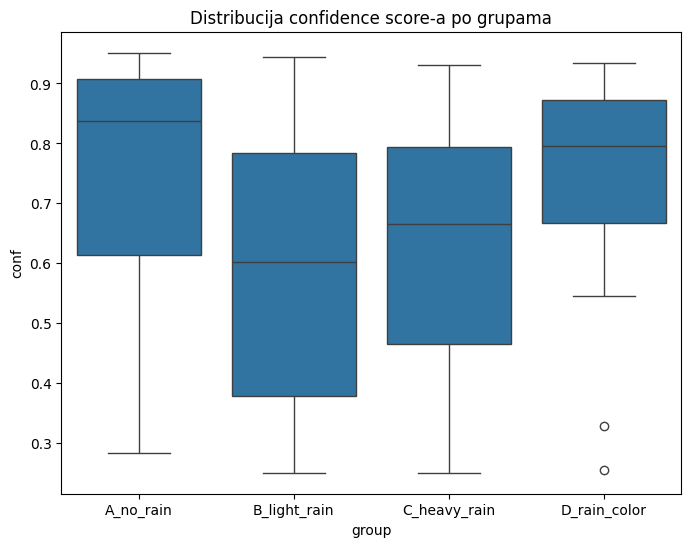

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

def load_csv(group):
    return pd.read_csv(os.path.join(RESULTS_DIR, group, 'detections.csv'))

df_A = load_csv('A_no_rain'); df_A['group'] = 'A_no_rain'
df_B = load_csv('B_light_rain'); df_B['group'] = 'B_light_rain'
df_C = load_csv('C_heavy_rain'); df_C['group'] = 'C_heavy_rain'
df_D = load_csv('D_rain_color'); df_D['group'] = 'D_rain_color'

df_all = pd.concat([df_A, df_B, df_C, df_D], ignore_index=True)

#confidence score statistics
summary = df_all.groupby('group')['conf'].agg(['mean','std','count']).reset_index()
print(summary)

#boxplot of confidence score distribution
plt.figure(figsize=(8,6))
sns.boxplot(data=df_all, x='group', y='conf')
plt.title('Distribucija confidence score-a po grupama')
plt.show()

In [ ]:
summary.to_csv(os.path.join(RESULTS_DIR, 'summary_metrics.csv'), index=False)

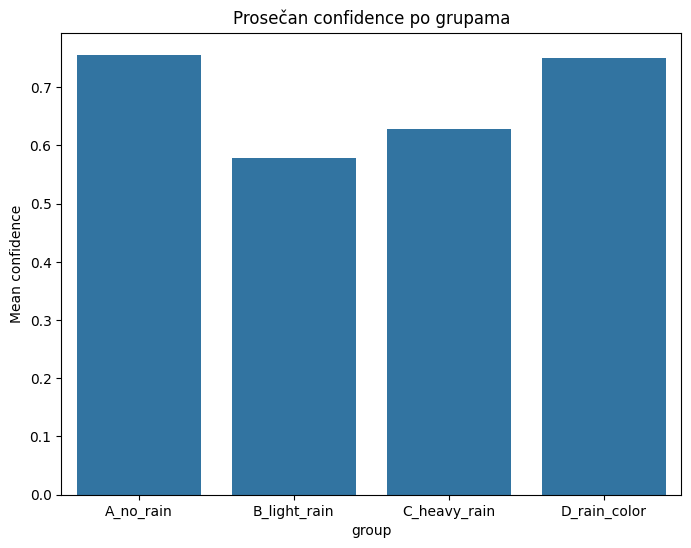

In [ ]:
summary = df_all.groupby('group')['conf'].mean().reset_index()

plt.figure(figsize=(8,6))
sns.barplot(data=summary, x='group', y='conf')
plt.title('Prosečan confidence po grupama')
plt.ylabel('Mean confidence')
plt.show()

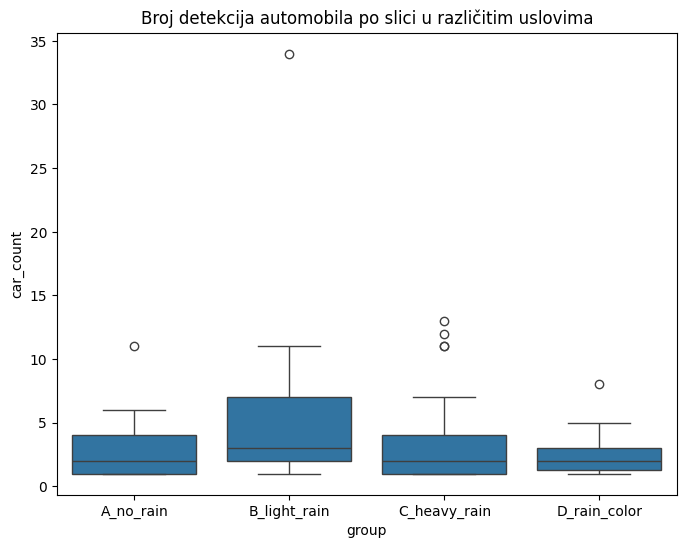

In [ ]:
df_counts = df_all.groupby(['group','image']).size().reset_index(name='car_count')

plt.figure(figsize=(8,6))
sns.boxplot(data=df_counts, x='group', y='car_count')
plt.title('Broj detekcija automobila po slici u različitim uslovima')
plt.show()

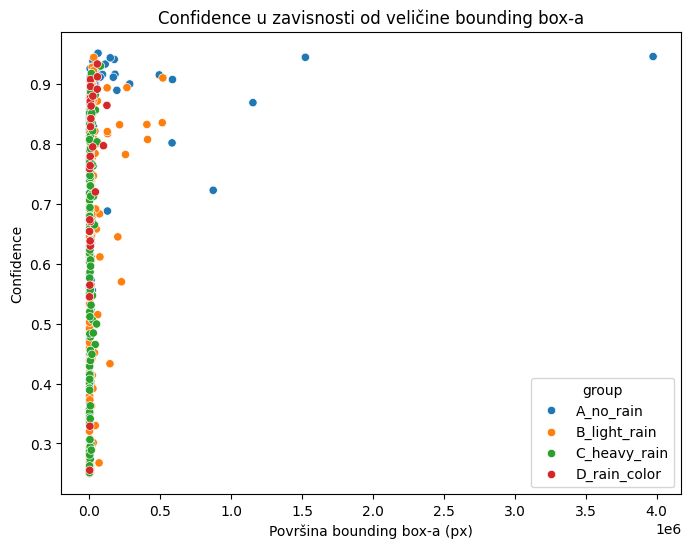

In [ ]:
df_all['box_area'] = (df_all['x2'] - df_all['x1']) * (df_all['y2'] - df_all['y1'])

plt.figure(figsize=(8,6))
sns.scatterplot(data=df_all, x='box_area', y='conf', hue='group')
plt.title('Confidence u zavisnosti od veličine bounding box-a')
plt.xlabel('Površina bounding box-a (px)')
plt.ylabel('Confidence')
plt.show()